# Notebook 2 · Comparación de algoritmos de clasificación supervisada

**Universidad de Cundinamarca · Especialización en Inteligencia Artificial**
**Curso:** Introducción a Machine Learning (2026-2) · **Docente:** Ing. Wilson Rojas Reales, PhD(c)
**Estudiante:** Juan Pablo Cristancho Tula
**Actividad:** R1-A2-S8 Informe de trabajo – ML Supervisado · Caso: *Predicción de defectos en producción (XYZ Inc.)*

---

**Actividad de la guía:** *modificar el script suministrado (`C1_CasoProduccion.py`) para incluir todas las métricas estudiadas e interpretar cada una de ellas para cada uno de los modelos implementados.*

### Modificaciones realizadas al script original
| # | Cambio | Motivo |
|---|--------|--------|
| 1 | Se agregan métricas: especificidad, VPN, tasa de falsos positivos y negativos, accuracy balanceado, F2, MCC, kappa de Cohen, ROC-AUC, AUC-PR y log-loss | Cubrir todas las métricas vistas y no depender solo de accuracy |
| 2 | Se desglosa la matriz de confusión en TN, FP, FN y TP | Interpretar los errores en términos del negocio |
| 3 | `StandardScaler` dentro de un `Pipeline` para Regresión Logística, KNN y SVM | Son modelos sensibles a la escala; el `Pipeline` evita fuga de información en la validación cruzada |
| 4 | Validación cruzada estratificada **repetida** (5 particiones × 10 repeticiones) y *Leave-One-Out* | Con 20 registros, una sola partición de 6 lotes no es confiable |
| 5 | Gráficas: matrices de confusión, curvas ROC, comparación de métricas y dispersión de la validación cruzada | Análisis visual de resultados con Matplotlib |
| 6 | Prueba de robustez con ruido de medición simulado | Diferenciar modelos que empatan con los datos originales |
| 7 | Criterio de desempate para el mejor modelo (F1 → recall → estabilidad) | El script original toma el primero de la tabla cuando hay empate |

## 1. Librerías y configuración

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     cross_val_predict, RepeatedStratifiedKFold,
                                     LeaveOneOut, StratifiedGroupKFold)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, matthews_corrcoef, cohen_kappa_score,
                             roc_auc_score, average_precision_score, log_loss, roc_curve,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORES = ["#1f4e79", "#d9822b", "#2e8b57", "#8e44ad", "#c0392b", "#7f7f7f"]

## 2. Dataset del caso de estudio

In [2]:
data = {
    "temperatura":     [70, 72, 75, 80, 85, 90, 95, 100, 78, 82, 88, 92, 97, 76, 73, 89, 94, 99, 81, 86],
    "presion":         [30, 32, 34, 36, 40, 42, 45, 48, 35, 37, 41, 43, 46, 33, 31, 42, 44, 47, 36, 39],
    "velocidad":       [120, 118, 115, 110, 105, 100, 95, 90, 112, 108, 102, 98, 93, 116, 119, 101, 96, 91, 109, 104],
    "horas_operacion": [2, 3, 4, 6, 8, 10, 12, 14, 5, 7, 9, 11, 13, 4, 3, 10, 12, 15, 6, 8],
    "vibracion":       [1.2, 1.4, 1.6, 2.0, 2.5, 3.0, 3.5, 4.0, 1.8, 2.2, 2.8, 3.2, 3.7, 1.5, 1.3, 3.1, 3.6, 4.2, 2.1, 2.6],
    "defectuoso":      [0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1],
}
df = pd.DataFrame(data)
VARS = ["temperatura", "presion", "velocidad", "horas_operacion", "vibracion"]
X, y = df[VARS], df["defectuoso"]

print("Registros:", len(df), "| Correctos (0):", (y == 0).sum(), "| Defectuosos (1):", (y == 1).sum())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print("Entrenamiento:", len(X_train), "lotes | Prueba:", len(X_test), "lotes", y_test.value_counts().sort_index().to_dict())

Registros: 20 | Correctos (0): 9 | Defectuosos (1): 11
Entrenamiento: 14 lotes | Prueba: 6 lotes {0: 3, 1: 3}


## 3. Línea base: resultados del script original

Se ejecuta el script de la guía **sin cambios** (mismos modelos, misma partición y `cross_val_score` con `cv=5`) para tener un punto de comparación.

In [3]:
modelos_originales = {
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "SVM": SVC(kernel="linear"),
    "Naive Bayes": GaussianNB(),
}
base = []
for nombre, m in modelos_originales.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    base.append({"Modelo": nombre,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p, zero_division=0),
                 "Recall": recall_score(y_test, p, zero_division=0),
                 "F1-score": f1_score(y_test, p, zero_division=0),
                 "Validación cruzada": cross_val_score(m, X, y, cv=5, scoring="accuracy").mean()})
df_base = pd.DataFrame(base)
print("Mejor modelo según el script original:", df_base.sort_values("F1-score", ascending=False).iloc[0]["Modelo"])
df_base.round(3)

Mejor modelo según el script original: Regresión Logística


,Modelo,Accuracy,Precision,Recall,F1-score,Validación cruzada
0,Regresión Logística,1.0,1.0,1.0,1.0,1.0
1,Árbol de Decisión,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0
3,KNN,1.0,1.0,1.0,1.0,1.0
4,SVM,1.0,1.0,1.0,1.0,1.0
5,Naive Bayes,1.0,1.0,1.0,1.0,1.0


**Interpretación:** con el script original los seis modelos obtienen 1.0 en todas las métricas, tanto en la prueba como en la validación cruzada. El script declara como mejor modelo a la Regresión Logística, pero no porque sea superior, sino porque **es el primero del diccionario** y el ordenamiento por F1 no tiene forma de desempatar. Esto justifica ampliar las métricas y la validación.

## 4. Script modificado: modelos y función de evaluación con todas las métricas

### Métricas incluidas (clase positiva = 1, lote defectuoso)
| Métrica | Fórmula | Pregunta que responde en el caso |
|---|---|---|
| Accuracy | (TP+TN)/N | ¿Qué proporción de lotes clasifica bien? |
| Accuracy balanceado | (Recall + Especificidad)/2 | ¿Acierta igual en ambas clases? |
| Precision | TP/(TP+FP) | De los lotes que marca como defectuosos, ¿cuántos lo son? |
| **Recall (sensibilidad)** | TP/(TP+FN) | De los lotes defectuosos, ¿cuántos detecta? **(métrica prioritaria)** |
| Especificidad | TN/(TN+FP) | De los lotes correctos, ¿cuántos libera sin alarma? |
| VPN | TN/(TN+FN) | Si dice "correcto", ¿qué tan confiable es? |
| Tasa de falsos positivos (FPR) | FP/(FP+TN) | Proporción de lotes buenos enviados a revisión innecesaria |
| Tasa de falsos negativos (FNR) | FN/(FN+TP) | Proporción de defectos que llegarían al cliente |
| F1-score | 2·P·R/(P+R) | Equilibrio entre precision y recall |
| F2-score | 5·P·R/(4P+R) | Como F1, pero da el doble de peso al recall |
| MCC | (TP·TN − FP·FN)/√[(TP+FP)(TP+FN)(TN+FP)(TN+FN)] | Correlación entre predicción y realidad (−1 a 1), robusta al desbalance |
| Kappa de Cohen | (p₀ − pₑ)/(1 − pₑ) | Acuerdo con la realidad descontando el azar |
| ROC-AUC | Área bajo la curva ROC | Capacidad de ordenar lotes por riesgo, sin depender del umbral |
| AUC-PR (Average Precision) | Área bajo la curva precision-recall | Igual que ROC-AUC pero enfocada en la clase positiva |
| Log-loss | −(1/N)·Σ[y·ln p + (1−y)·ln(1−p)] | Calidad de las probabilidades (menor es mejor) |

In [4]:
def crear_modelos():
    # Modelos sensibles a la escala -> Pipeline con StandardScaler
    return {
        "Regresión Logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "Árbol de Decisión":   DecisionTreeClassifier(random_state=42),
        "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
        "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
        "SVM":                 make_pipeline(StandardScaler(), SVC(kernel="linear", probability=True, random_state=42)),
        "Naive Bayes":         GaussianNB(),
    }

def puntaje_continuo(modelo, X_):
    # Puntaje para ROC/PR: en SVM se usa la distancia al hiperplano (decision_function);
    # en el resto, la probabilidad estimada de la clase 1
    estimador = modelo.steps[-1][1] if hasattr(modelo, "steps") else modelo
    if isinstance(estimador, SVC):
        return modelo.decision_function(X_)
    return modelo.predict_proba(X_)[:, 1]

def evaluar(y_real, y_pred, score=None, proba=None):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else 0.0
    r = {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
         "Accuracy": accuracy_score(y_real, y_pred),
         "Accuracy balanceado": balanced_accuracy_score(y_real, y_pred),
         "Precision": precision_score(y_real, y_pred, zero_division=0),
         "Recall": recall_score(y_real, y_pred, zero_division=0),
         "Especificidad": div(tn, tn + fp),
         "VPN": div(tn, tn + fn),
         "FPR": div(fp, fp + tn),
         "FNR": div(fn, fn + tp),
         "F1-score": f1_score(y_real, y_pred, zero_division=0),
         "F2-score": fbeta_score(y_real, y_pred, beta=2, zero_division=0),
         "MCC": matthews_corrcoef(y_real, y_pred),
         "Kappa": cohen_kappa_score(y_real, y_pred)}
    if score is not None:
        r["ROC-AUC"] = roc_auc_score(y_real, score)
        r["AUC-PR"] = average_precision_score(y_real, score)
    if proba is not None:
        r["Log-loss"] = log_loss(y_real, np.clip(proba, 1e-6, 1 - 1e-6), labels=[0, 1])
    return r

## 5. Entrenamiento y evaluación en el conjunto de prueba (30 %)

In [5]:
modelos = crear_modelos()
resultados, predicciones, puntajes = [], {}, {}

for nombre, modelo in modelos.items():
    print("=" * 70); print("MODELO:", nombre); print("=" * 70)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    score = puntaje_continuo(modelo, X_test)
    proba = modelo.predict_proba(X_test)[:, 1]
    predicciones[nombre], puntajes[nombre] = y_pred, score

    fila = {"Modelo": nombre, **evaluar(y_test, y_pred, score, proba)}
    resultados.append(fila)

    print("Matriz de confusión [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=["Correcto", "Defectuoso"], zero_division=0))

df_test = pd.DataFrame(resultados).set_index("Modelo")
df_test.to_csv("resultados/metricas_prueba.csv")

MODELO: Regresión Logística
Matriz de confusión [[TN FP] [FN TP]]:
 [[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

MODELO: Árbol de Decisión
Matriz de confusión [[TN FP] [FN TP]]:
 [[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

MODELO: Random Forest


Matriz de confusión [[TN FP] [FN TP]]:
 [[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

MODELO: KNN
Matriz de confusión [[TN FP] [FN TP]]:
 [[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

MODELO: SVM


Matriz de confusión [[TN FP] [FN TP]]:
 [[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

MODELO: Naive Bayes
Matriz de confusión [[TN FP] [FN TP]]:
 [[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Correcto       1.00      1.00      1.00         3
  Defectuoso       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



In [6]:
print("TABLA COMPARATIVA – CONJUNTO DE PRUEBA (6 lotes)")
df_test.round(3).T

TABLA COMPARATIVA – CONJUNTO DE PRUEBA (6 lotes)


Modelo,Regresión Logística,Árbol de Decisión,Random Forest,KNN,SVM,Naive Bayes
TN,3.000,3.0,3.000,3.0,3.000,3.0
FP,0.000,0.0,0.000,0.0,0.000,0.0
FN,0.000,0.0,0.000,0.0,0.000,0.0
TP,3.000,3.0,3.000,3.0,3.000,3.0
Accuracy,1.000,1.0,1.000,1.0,1.000,1.0
Accuracy balanceado,1.000,1.0,1.000,1.0,1.000,1.0
Precision,1.000,1.0,1.000,1.0,1.000,1.0
Recall,1.000,1.0,1.000,1.0,1.000,1.0
Especificidad,1.000,1.0,1.000,1.0,1.000,1.0
VPN,1.000,1.0,1.000,1.0,1.000,1.0


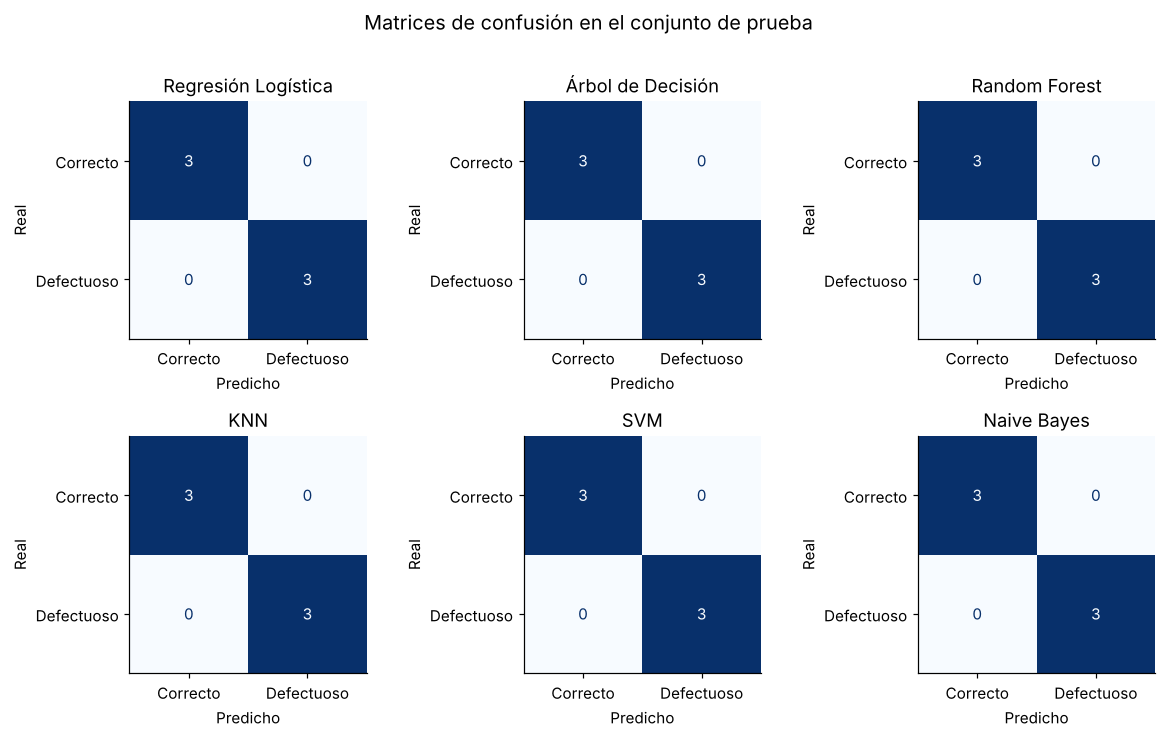

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for ax, (nombre, y_pred) in zip(axes.ravel(), predicciones.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Correcto", "Defectuoso"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre); ax.grid(False)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
fig.suptitle("Matrices de confusión en el conjunto de prueba", y=1.01, fontsize=13)
plt.tight_layout(); plt.savefig("figuras/fig08_matrices_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

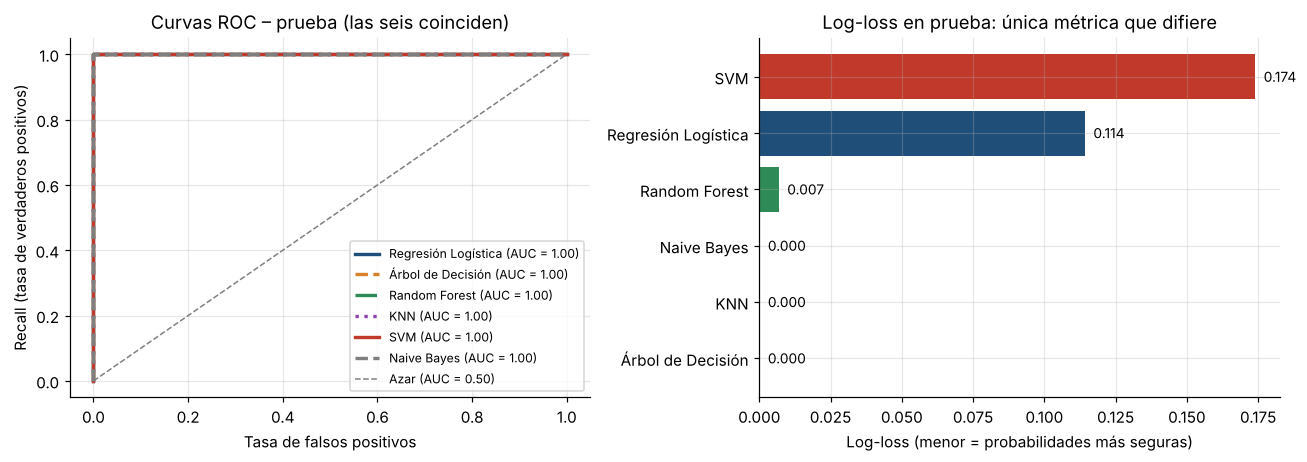

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for (nombre, sc), col, ls in zip(puntajes.items(), COLORES, ["-", "--", "-.", ":", "-", "--"]):
    fpr, tpr, _ = roc_curve(y_test, sc)
    axes[0].plot(fpr, tpr, lw=2.2, color=col, ls=ls, label=f"{nombre} (AUC = {roc_auc_score(y_test, sc):.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="grey", lw=1, label="Azar (AUC = 0.50)")
axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Recall (tasa de verdaderos positivos)")
axes[0].set_title("Curvas ROC – prueba (las seis coinciden)"); axes[0].legend(fontsize=8, loc="lower right")

ll = df_test["Log-loss"].sort_values()
axes[1].barh(ll.index, ll.values, color=[COLORES[list(df_test.index).index(n)] for n in ll.index])
for i, v in enumerate(ll.values):
    axes[1].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
axes[1].set_xlabel("Log-loss (menor = probabilidades más seguras)")
axes[1].set_title("Log-loss en prueba: única métrica que difiere")
plt.tight_layout(); plt.savefig("figuras/fig09_roc.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación de las métricas en el conjunto de prueba (6 lotes: 3 correctos y 3 defectuosos)**

Los seis modelos obtienen la misma matriz de confusión: **TN = 3, FP = 0, FN = 0, TP = 3**.

* **Accuracy = 1.0 y accuracy balanceado = 1.0:** todos los lotes de prueba quedan bien clasificados, y el acierto es igual en ambas clases.
* **Precision = 1.0:** ningún lote correcto se envió a revisión innecesaria (cero falsos positivos, FPR = 0). No hay sobrecostos de inspección ni de detención de línea.
* **Recall = 1.0 (FNR = 0):** los tres lotes defectuosos fueron detectados; ninguno llegaría al cliente. Es la métrica prioritaria del caso.
* **Especificidad = 1.0 y VPN = 1.0:** cuando el modelo libera un lote como correcto, acierta siempre.
* **F1 = F2 = 1.0:** como precision y recall son iguales a 1, ambas medias armónicas también lo son, sin importar el peso dado al recall.
* **MCC = 1.0 y Kappa = 1.0:** concordancia perfecta entre predicción y realidad, descontando el azar.
* **ROC-AUC = AUC-PR = 1.0:** todos los modelos asignan un puntaje de riesgo mayor a cada lote defectuoso que a cualquier lote correcto.
* **Log-loss:** es la **única métrica que diferencia a los modelos** en la prueba. Árbol, KNN y Naive Bayes dan probabilidades de 0 o 1 (log-loss ≈ 0), Random Forest 0.007, Regresión Logística 0.114 y SVM 0.174. Un log-loss mayor no significa que el modelo falle: la Regresión Logística entrega probabilidades más moderadas (por ejemplo 0.275 para el lote 4, que está cerca de la frontera), lo cual es más honesto que una certeza absoluta en un dataset de 20 registros.

**Conclusión:** con 6 lotes de prueba, la partición no permite distinguir los modelos. Un solo error bajaría el accuracy a 0.83.

## 6. Validación cruzada estratificada repetida (5 × 10 = 50 particiones)

Un conjunto de prueba de 6 lotes es demasiado pequeño: cada lote pesa 16.7 % del accuracy. Se usa `RepeatedStratifiedKFold` para evaluar cada modelo en 50 particiones diferentes y reportar **media ± desviación estándar**.

In [9]:
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1-score": "f1", "ROC-AUC": "roc_auc", "Accuracy balanceado": "balanced_accuracy"}

cv_res, cv_raw = [], {}
for nombre, modelo in crear_modelos().items():
    r = cross_validate(modelo, X, y, cv=cv_rep, scoring=scoring, error_score="raise")
    cv_raw[nombre] = r
    fila = {"Modelo": nombre}
    for k in scoring:
        fila[f"{k} (media)"] = r[f"test_{k}"].mean()
        fila[f"{k} (desv.)"] = r[f"test_{k}"].std()
    cv_res.append(fila)

df_cv = pd.DataFrame(cv_res).set_index("Modelo")
df_cv.to_csv("resultados/validacion_cruzada_repetida.csv")
df_cv[[c for c in df_cv.columns if "media" in c]].round(3)

,Accuracy (media),Precision (media),Recall (media),F1-score (media),ROC-AUC (media),Accuracy balanceado (media)
Modelo,,,,,,
Regresión Logística,1.000,1.000,1.000,1.000,1.000,1.000
Árbol de Decisión,0.980,0.980,0.967,0.970,0.983,0.983
Random Forest,0.990,1.000,0.983,0.989,1.000,0.992
KNN,0.990,0.987,1.000,0.992,1.000,0.990
SVM,0.990,0.987,1.000,0.992,1.000,0.990
Naive Bayes,0.995,0.993,1.000,0.996,1.000,0.995


In [10]:
df_cv[[c for c in df_cv.columns if "desv" in c]].round(3)

,Accuracy (desv.),Precision (desv.),Recall (desv.),F1-score (desv.),ROC-AUC (desv.),Accuracy balanceado (desv.)
Modelo,,,,,,
Regresión Logística,0.000,0.000,0.000,0.000,0.000,0.000
Árbol de Decisión,0.098,0.140,0.167,0.155,0.083,0.083
Random Forest,0.049,0.000,0.083,0.054,0.000,0.042
KNN,0.049,0.065,0.000,0.039,0.000,0.049
SVM,0.049,0.065,0.000,0.039,0.000,0.049
Naive Bayes,0.035,0.047,0.000,0.028,0.000,0.035


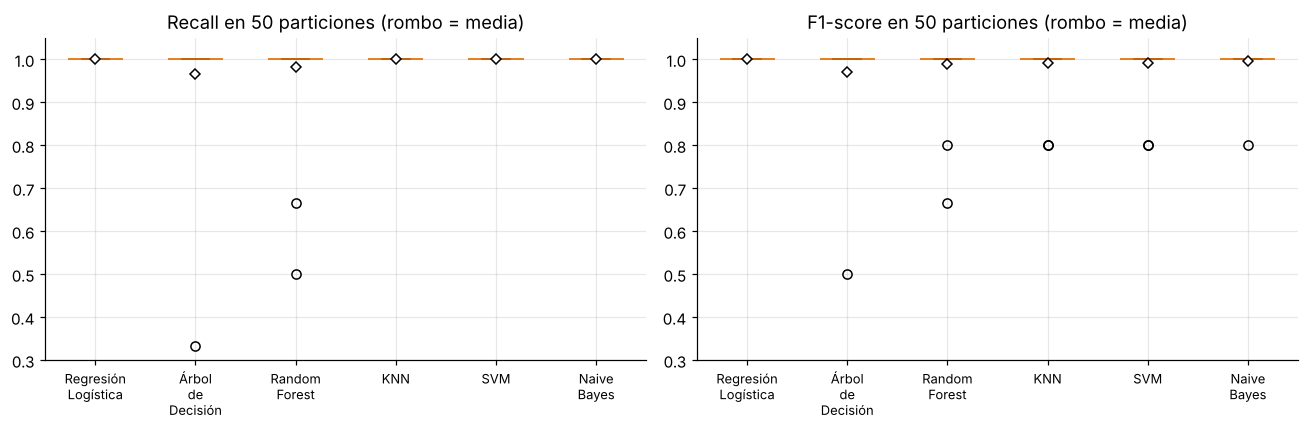

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
nombres = list(cv_raw)
for ax, met in zip(axes, ["Recall", "F1-score"]):
    datos = [cv_raw[n][f"test_{met}"] for n in nombres]
    bp = ax.boxplot(datos, patch_artist=True, widths=0.55, showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="k", markersize=5))
    for patch, col in zip(bp["boxes"], COLORES):
        patch.set_facecolor(col); patch.set_alpha(0.55)
    ax.set_xticks(range(1, 7)); ax.set_xticklabels([n.replace(" ", "\n") for n in nombres], fontsize=8.5)
    ax.set_ylim(0.3, 1.05); ax.set_title(f"{met} en 50 particiones (rombo = media)")
plt.tight_layout(); plt.savefig("figuras/fig10_cv_boxplot.png", dpi=200, bbox_inches="tight"); plt.show()

### Validación *Leave-One-Out* (cada lote se predice con un modelo entrenado con los otros 19)

In [12]:
loo = []
for nombre, modelo in crear_modelos().items():
    p = cross_val_predict(modelo, X, y, cv=LeaveOneOut())
    loo.append({"Modelo": nombre, **{k: v for k, v in evaluar(y, p).items()
                if k in ["TN", "FP", "FN", "TP", "Accuracy", "Recall", "Precision", "F1-score"]},
                "Lotes mal clasificados": list(np.where(p != y)[0] + 1)})
df_loo = pd.DataFrame(loo).set_index("Modelo")
df_loo.to_csv("resultados/leave_one_out.csv")
df_loo

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-score,Lotes mal clasificados
Modelo,,,,,,,,,
Regresión Logística,9,0,0,11,1.0,1.0,1.0,1.0,[]
Árbol de Decisión,9,0,0,11,1.0,1.0,1.0,1.0,[]
Random Forest,9,0,0,11,1.0,1.0,1.0,1.0,[]
KNN,9,0,0,11,1.0,1.0,1.0,1.0,[]
SVM,9,0,0,11,1.0,1.0,1.0,1.0,[]
Naive Bayes,9,0,0,11,1.0,1.0,1.0,1.0,[]


**Interpretación de la validación cruzada:**

* La **Regresión Logística** es el único modelo con 1.0 en todas las métricas en las 50 particiones y desviación 0: la frontera lineal que aprende es estable sin importar qué lotes queden en entrenamiento.
* **Naive Bayes, KNN y SVM** mantienen **recall = 1.0** en todas las particiones (nunca dejan pasar un defecto); sus pequeños errores son falsos positivos, por lo que su precision baja a 0.987–0.993. Para el negocio este es el tipo de error menos costoso.
* **Random Forest** tiene precision = 1.0 pero recall = 0.983: en algunas particiones deja pasar un lote defectuoso. Es el error que la empresa quiere evitar.
* El **Árbol de Decisión** es el más débil e inestable (recall 0.967 ± 0.167; F1 0.970 ± 0.155). Al apoyarse en un único corte, cuando el lote frontera queda fuera del entrenamiento el corte se desplaza y aparecen falsos negativos.
* Con *Leave-One-Out* (19 lotes para entrenar) **todos los modelos clasifican bien los 20 lotes**: los errores de la validación 5×10 aparecen solo cuando se entrena con 16 lotes, lo que muestra que el desempeño depende del tamaño de la muestra de entrenamiento.

## 7. Prueba de robustez con ruido de medición (simulación)

Los datos originales son casi perfectamente separables, por lo que todos los modelos empatan. Para saber **cuál resiste mejor condiciones más realistas** se simula ruido de sensor: cada uno de los 20 lotes se replica 10 veces y a cada variable se le suma ruido gaussiano con desviación igual a una fracción *k* de su desviación estándar (k = 0.25, 0.50 y 0.75). La etiqueta de cada réplica es la del lote original.

Para evitar fuga de información, se usa `StratifiedGroupKFold`: **todas las réplicas de un mismo lote quedan en el mismo pliegue**, así el modelo nunca se evalúa con copias de lotes que vio en el entrenamiento. Se repite con 5 semillas distintas.

> Esta sección es un **experimento de sensibilidad** con datos derivados; no reemplaza la evaluación con datos reales de la planta.

In [13]:
def robustez(k, semillas=(0, 1, 2, 3, 4), reps=10):
    filas = []
    for nombre in crear_modelos():
        mets = {"Accuracy": [], "Precision": [], "Recall": [], "F1-score": []}
        for s in semillas:
            rng = np.random.default_rng(s)
            Xa = np.repeat(X.values, reps, axis=0) + rng.normal(0, 1, (len(X) * reps, X.shape[1])) * X.std().values * k
            ya = np.repeat(y.values, reps)
            grupos = np.repeat(np.arange(len(X)), reps)
            cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=s)
            r = cross_validate(crear_modelos()[nombre], pd.DataFrame(Xa, columns=VARS), ya, groups=grupos, cv=cv,
                               scoring={"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1-score": "f1"})
            for m in mets:
                mets[m].append(r[f"test_{m}"].mean())
        filas.append({"Modelo": nombre, "Ruido k": k, **{m: np.mean(v) for m, v in mets.items()}})
    return filas

df_rob = pd.DataFrame(sum([robustez(k) for k in (0.25, 0.50, 0.75)], []))
df_rob.to_csv("resultados/robustez_ruido.csv", index=False)
df_rob.pivot(index="Modelo", columns="Ruido k", values=["Recall", "F1-score"]).round(3)

Recall               F1-score              
Ruido k               0.25   0.50   0.75     0.25   0.50   0.75
Modelo                                                         
KNN                  0.976  0.947  0.908    0.976  0.940  0.907
Naive Bayes          0.970  0.925  0.906    0.975  0.943  0.918
Random Forest        0.976  0.943  0.907    0.979  0.937  0.903
Regresión Logística  0.973  0.950  0.920    0.976  0.953  0.919
SVM                  0.976  0.937  0.917    0.977  0.941  0.919
Árbol de Decisión    0.956  0.912  0.859    0.957  0.906  0.867

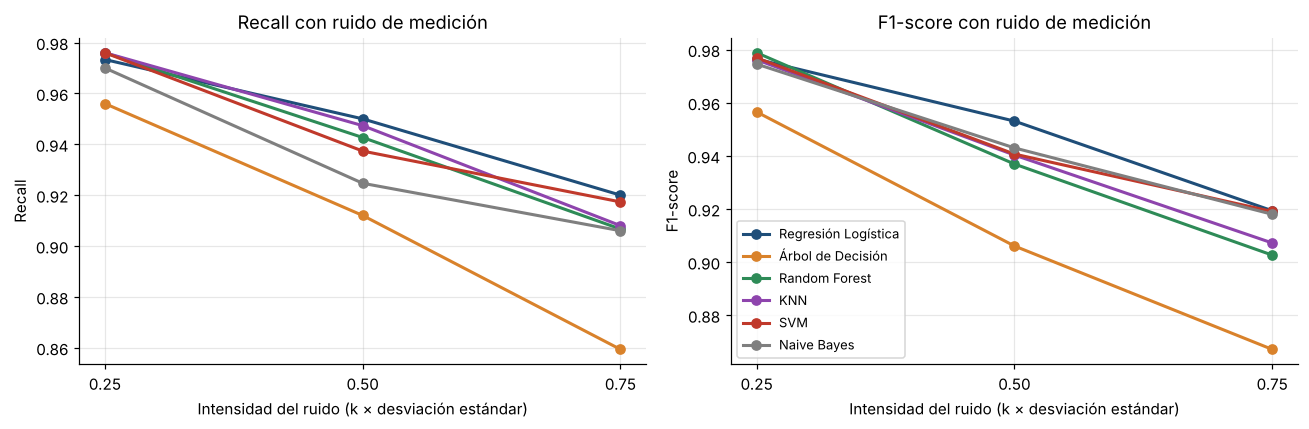

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, met in zip(axes, ["Recall", "F1-score"]):
    for (nombre, g), col in zip(df_rob.groupby("Modelo", sort=False), COLORES):
        ax.plot(g["Ruido k"], g[met], marker="o", lw=2, color=col, label=nombre)
    ax.set_xlabel("Intensidad del ruido (k × desviación estándar)"); ax.set_ylabel(met)
    ax.set_xticks([0.25, 0.5, 0.75]); ax.set_title(f"{met} con ruido de medición")
axes[1].legend(fontsize=8.5, loc="lower left")
plt.tight_layout(); plt.savefig("figuras/fig11_robustez.png", dpi=200, bbox_inches="tight"); plt.show()

**Interpretación de la prueba de robustez:**

* Todos los modelos pierden desempeño cuando aumenta el ruido, lo cual es esperado: los lotes cercanos a la frontera (temperatura ≈ 82–86, vibración ≈ 2.2–2.6) empiezan a cruzarla.
* Con ruido alto (k = 0.75), la **Regresión Logística** conserva el mayor recall (0.920) y F1 (0.919), seguida muy de cerca por **SVM lineal** (recall 0.917, F1 0.919). Ambos son modelos lineales con regularización, lo que los hace menos sensibles a mediciones atípicas.
* **Naive Bayes, KNN y Random Forest** quedan en un segundo grupo (recall ≈ 0.906–0.908).
* El **Árbol de Decisión** es el que más se degrada (recall 0.859): un único árbol sin poda memoriza cortes exactos y es muy sensible a pequeñas variaciones en los datos, que es justamente la debilidad que Random Forest corrige al promediar 100 árboles.

## 8. Comparación visual de métricas

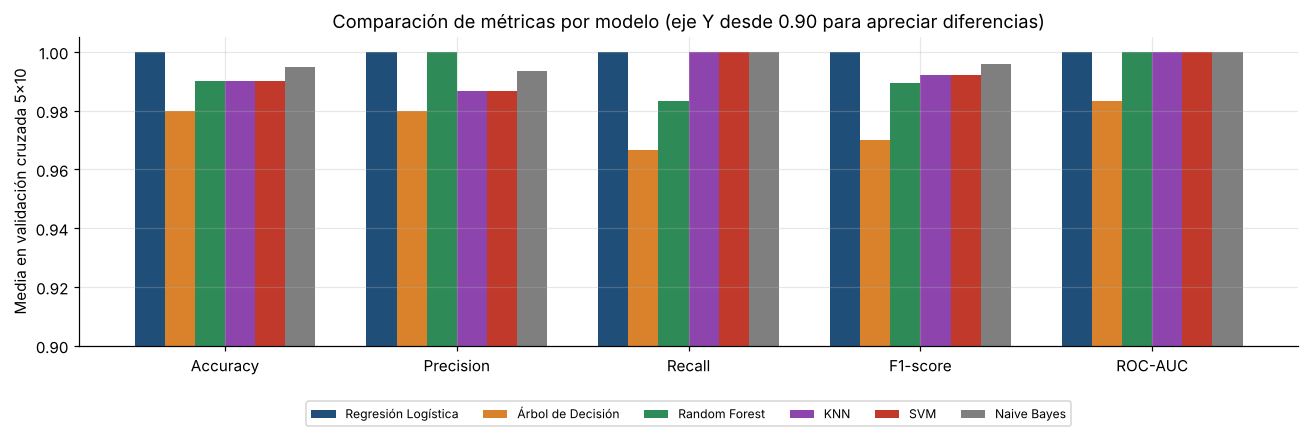

In [15]:
mets = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
tabla = df_cv[[f"{m} (media)" for m in mets]]
tabla.columns = mets
fig, ax = plt.subplots(figsize=(12, 4.2))
ancho = 0.13
for i, (nombre, fila) in enumerate(tabla.iterrows()):
    ax.bar(np.arange(len(mets)) + (i - 2.5) * ancho, fila.values, ancho, label=nombre, color=COLORES[i])
ax.set_xticks(range(len(mets))); ax.set_xticklabels(mets)
ax.set_ylim(0.9, 1.005); ax.set_ylabel("Media en validación cruzada 5×10")
ax.set_title("Comparación de métricas por modelo (eje Y desde 0.90 para apreciar diferencias)")
ax.legend(ncol=6, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.28))
plt.tight_layout(); plt.savefig("figuras/fig12_comparacion_metricas.png", dpi=200, bbox_inches="tight"); plt.show()

### Árbol de decisión aprendido (interpretabilidad)

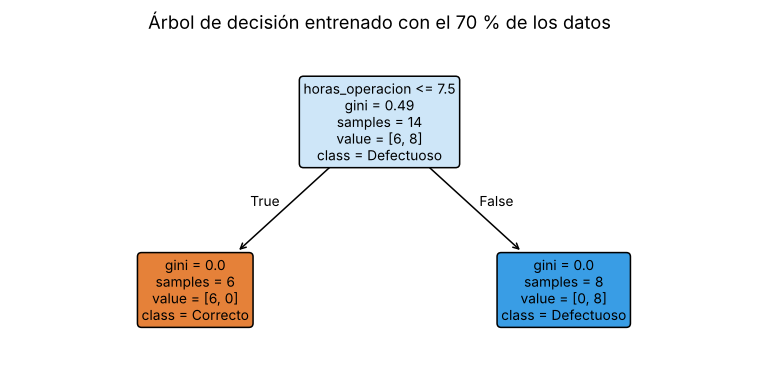

horas_operacion    0.23
temperatura        0.22
vibracion          0.21
presion            0.19
velocidad          0.15
Name: Importancia (Random Forest), dtype: float64

In [16]:
arbol = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(7, 3.6))
plot_tree(arbol, feature_names=VARS, class_names=["Correcto", "Defectuoso"], filled=True, rounded=True, ax=ax, fontsize=9)
ax.set_title("Árbol de decisión entrenado con el 70 % de los datos")
plt.tight_layout(); plt.savefig("figuras/fig13_arbol.png", dpi=200, bbox_inches="tight"); plt.show()

rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
pd.Series(rf.feature_importances_, index=VARS).sort_values(ascending=False).round(3).rename("Importancia (Random Forest)")

**Interpretación:** el árbol aprendido usa una sola regla: **si horas_operacion > 7.5 el lote es defectuoso**. Esta regla es muy fácil de explicar a un supervisor de planta, pero depende de un único umbral, lo que explica su inestabilidad. En Random Forest la importancia se reparte de forma casi uniforme entre las cinco variables (0.15–0.23), lo que confirma que, por su alta correlación, todas aportan información parecida; las horas de operación y la temperatura aparecen como las más importantes.

## 9. Selección del mejor modelo

El script original ordena por F1-score y toma la primera fila; cuando todos empatan en 1.0 el "ganador" depende solo del orden del diccionario. Aquí se aplica un criterio en cascada alineado con el negocio:

1. **F1-score** medio en validación cruzada repetida.
2. **Recall** medio (desempate: menos defectos que llegan al cliente).
3. **Recall bajo ruido** (k = 0.75) como medida de robustez.
4. Menor **desviación estándar** del F1 (estabilidad).

In [17]:
rob_k = df_rob[df_rob["Ruido k"] == 0.75].set_index("Modelo")
ranking = pd.DataFrame({
    "F1 (CV)":        df_cv["F1-score (media)"],
    "Recall (CV)":    df_cv["Recall (media)"],
    "Recall ruido":   rob_k["Recall"],
    "F1 ruido":       rob_k["F1-score"],
    "Desv. F1 (CV)":  df_cv["F1-score (desv.)"],
}).round(4)
ranking = ranking.sort_values(["F1 (CV)", "Recall (CV)", "Recall ruido", "Desv. F1 (CV)"],
                              ascending=[False, False, False, True])
ranking.to_csv("resultados/ranking_final.csv")
print("Mejor modelo:", ranking.index[0])
ranking

Mejor modelo: Regresión Logística


,F1 (CV),Recall (CV),Recall ruido,F1 ruido,Desv. F1 (CV)
Modelo,,,,,
Regresión Logística,1.0000,1.0000,0.9200,0.9193,0.0000
Naive Bayes,0.9960,1.0000,0.9060,0.9180,0.0280
SVM,0.9920,1.0000,0.9173,0.9190,0.0392
KNN,0.9920,1.0000,0.9080,0.9072,0.0392
Random Forest,0.9893,0.9833,0.9067,0.9026,0.0539
Árbol de Decisión,0.9700,0.9667,0.8593,0.8671,0.1552


## 10. Conclusiones

* **Mejor modelo: Regresión Logística.** Obtiene F1 = 1.0 y recall = 1.0 en la prueba, en las 50 particiones de validación cruzada y en *Leave-One-Out*, sin variabilidad, y es el que mejor conserva el recall con ruido de medición. Además entrega probabilidades interpretables y coeficientes que indican el efecto de cada variable, lo que facilita definir un umbral de alerta en planta.
* **SVM lineal** es una alternativa casi equivalente; **Naive Bayes** y **KNN** también mantienen recall perfecto en validación cruzada, con errores que solo son falsos positivos.
* **Random Forest** y, sobre todo, el **Árbol de Decisión** son los que presentan falsos negativos en validación cruzada; el árbol, en cambio, gana en interpretabilidad (una sola regla: horas de operación > 7.5).
* El script original no podía elegir un ganador real porque todas las métricas empataban en 1.0 con una prueba de 6 lotes. Ampliar las métricas (log-loss, MCC, F2), usar validación cruzada repetida y evaluar la robustez permitió diferenciar los modelos con criterios alineados al negocio.
* **Limitación principal:** el dataset es simulado, pequeño (20 lotes) y casi linealmente separable. Antes de implementar el modelo se recomienda recolectar datos históricos reales de la planta y volver a validar, priorizando el recall.